<div style="font-size: 28px; font-weight: bold; text-align: center; margin-bottom: 20px;">
    Отчёт по лабораторной работе
</div>

<div style="font-size: 20px; margin-bottom: 5px;">
    <b>Дисциплина:</b> <i>Синтез речи</i>
</div>

<div style="font-size: 20px; margin-bottom: 5px;">
    <b>Лабораторная работа №1:</b> <i>Нормализация текста</i>
</div>


<hr>

<div style="font-size: 20px; margin-bottom: 5px;">
    <b>Студент:</b> Рябой Евгений Э., группа М4221
</div>


<hr>


В этой работе посмотрю на текстовую часть корпуса RUSLAN и попробую понять, какие строки потом нужно исправлять, а какие лучше вообще не брать для обучения.
В итоге нужны две части:
- TextNormalizer - исправляет простые случаи;
- TextFilter - решает, оставлять строку или нет.
Главное здесь не «исправить вообще всё», а не сделать текст отличающимся от того, что реально произносится в аудио.

## План работы

Будем двигаться последовательно:

1. Проверим окружение и подключим библиотеки.
2. Загрузим метаданные RUSLAN.
3. Проведём небольшой EDA: размер данных, пропуски, повторы, длины фраз.
4. Посмотрим на символы и основные типы потенциально ненормализованных данных.
5. Изучим `dev_sentences.csv`, на котором будем проверять фильтр.
6. После реализации `TextFilter` посчитаем `precision`, `recall` и `F1`.
7. После реализации `TextNormalizer` посмотрим примеры его работы.
8. Проверим итоговый очищенный файл корпуса.


## Окружение

Работа запускалась на Python 3.11. 
Для анализа здесь в основном нужны pandas, регулярные выражения и matplotlib.

PyTorch и CUDA для этой части лабораторной не используются.

#### Импорты

Подключу библиотеки и заодно выведу версии основных пакетов.

In [7]:
import sys
import csv
import re
import platform
import unicodedata
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

%matplotlib inline

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())

for package in ["pandas", "numpy", "scikit-learn", "matplotlib"]:
    print(f"{package}: {version(package)}")

Python: 3.11.16
OS: Windows-10-10.0.22631-SP0
pandas: 3.0.6
numpy: 2.4.6
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Пути к данным

Ноутбук рассчитан на запуск из папки лабораторной работы `lab1_text`.

Ожидаемая структура проекта:

```text
data/
├── RUSLAN/
│   └── metadata_RUSLAN_22200.csv
└── metadata_RUSLAN_22200_normalized.csv

labs/
└── lab1_text/
    ├── data/
    │   └── dev_sentences.csv
    ├── text_filter.py
    ├── text_normalizer.py
    ├── preprocess_ruslan.py
    └── report.ipynb
```

Чтобы ноутбук было удобнее открывать отдельно, добавим несколько запасных путей.  
Это не влияет на саму обработку данных.

In [8]:
METADATA_PATH = Path("../../data/RUSLAN/metadata_RUSLAN_22200.csv")
DEV_SET_PATH = Path("data/dev_sentences.csv")
NORMALIZED_PATH = Path("../../data/metadata_RUSLAN_22200_normalized.csv")

print("RUSLAN metadata:", METADATA_PATH)
print("Dev set:", DEV_SET_PATH)
print("Normalized metadata:", NORMALIZED_PATH)

RUSLAN metadata: ..\..\data\RUSLAN\metadata_RUSLAN_22200.csv
Dev set: data\dev_sentences.csv
Normalized metadata: ..\..\data\metadata_RUSLAN_22200_normalized.csv


Сначала проверяю, что исходный RUSLAN и dev-набор действительно нашлись. Итогового файла может ещё не быть, если preprocess_ruslan.py пока не запускался.

# Часть 1. EDA RUSLAN

## Загрузка метаданных

Исходный файл RUSLAN содержит две колонки:

```text
id | text
```

Для чтения ещё отключаю обработку кавычек как специальных CSV-символов, потому что они встречаются прямо в тексте.

In [9]:
assert METADATA_PATH is not None, "Не найден metadata_RUSLAN_22200.csv"

ruslan = pd.read_csv(
    METADATA_PATH,
    sep="|",
    names=["id", "text"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

print("Размер таблицы:", ruslan.shape)
ruslan.head(10)

Размер таблицы: (22200, 2)


,id,text
0,000000_RUSLAN,С тревожным чувством берусь я за перо.
1,000001_RUSLAN,Кого интересуют признания литературного неудач...
2,000002_RUSLAN,Что поучительного в его исповеди?
3,000003_RUSLAN,Да и жизнь моя лишена внешнего трагизма.
4,000004_RUSLAN,Я абсолютно здоров.
5,000005_RUSLAN,У меня есть любящая родня.
6,000006_RUSLAN,"Мне всегда готовы предоставить работу, которая..."
7,000007_RUSLAN,"Мало того, я обладаю преимуществами."
8,000008_RUSLAN,Мне без труда удается располагать к себе людей.
9,000009_RUSLAN,"Я совершил десятки поступков, уголовно наказуе..."


Получилось 22 200 строк. По первым примерам видно, что большая часть фраз уже выглядит нормально, поэтому дальше интереснее искать редкие проблемные случаи.

## Пропуски и повторы

Сначала посмотрим на самые простые проблемы:

- есть ли пропущенные значения;
- встречаются ли пустые строки;
- уникальны ли `id`;
- есть ли полностью повторяющиеся строки;
- повторяется ли один и тот же текст у разных записей.

Повтор текста сам по себе не означает ошибку: одна и та же фраза теоретически может встречаться в корпусе несколько раз.

In [10]:
quality_summary = pd.Series({
    "Количество строк": len(ruslan),
    "Уникальных id": ruslan["id"].nunique(),
    "Пропусков в id": ruslan["id"].isna().sum(),
    "Пропусков в text": ruslan["text"].isna().sum(),
    "Пустых текстов": ruslan["text"].fillna("").str.strip().eq("").sum(),
    "Полных дубликатов строк": ruslan.duplicated().sum(),
    "Повторяющихся текстов": ruslan["text"].duplicated().sum(),
})

quality_summary.to_frame("Значение")

,Значение
Количество строк,22200
Уникальных id,22200
Пропусков в id,0
Пропусков в text,0
Пустых текстов,0
Полных дубликатов строк,0
Повторяющихся текстов,260


С данными в целом всё нормально: пропусков нет, пустых строк нет, все id уникальные.
Одинаковый текст встречается 260 раз, но удалять его только из-за этого не буду - аудиофайлы при этом разные.

## Длина фраз

Посчитаю длину строки в символах и примерное количество слов


In [11]:
ruslan["n_chars"] = ruslan["text"].str.len()
ruslan["n_words"] = ruslan["text"].str.split().str.len()

ruslan[["n_chars", "n_words"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2)

,n_chars,n_words
count,22200.00,22200.00
mean,80.79,12.03
std,41.50,6.23
min,10.00,1.00
25%,55.00,8.00
50%,85.00,12.00
75%,102.00,15.00
90%,111.00,18.00
95%,115.00,20.00
99%,233.00,32.00


#### Визуализируем распределение длины

Посмотрим на распределение по символам и словам.

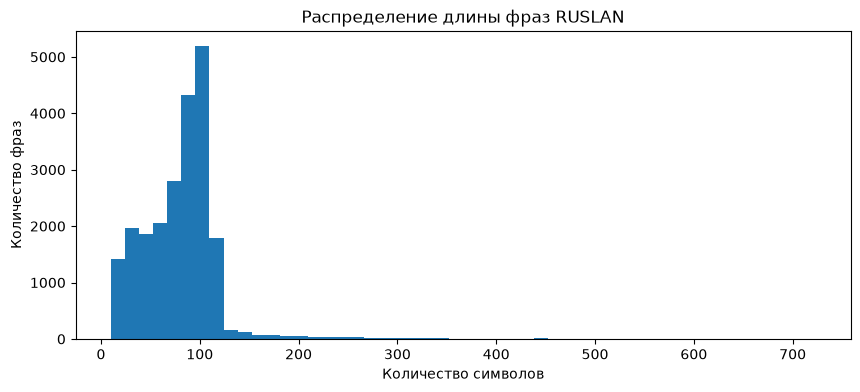

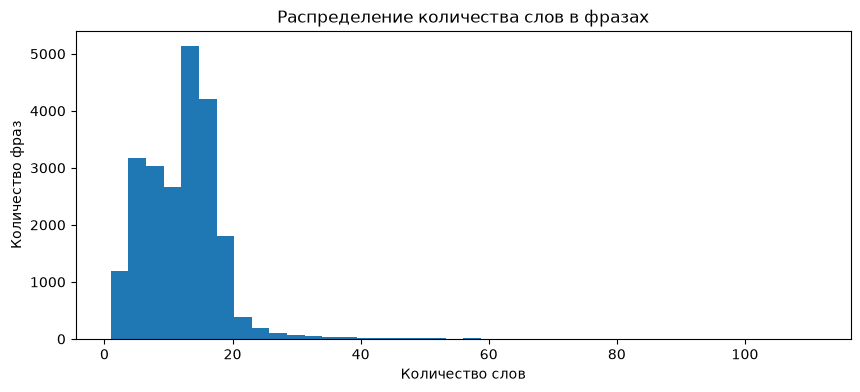

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(ruslan["n_chars"], bins=50)
plt.xlabel("Количество символов")
plt.ylabel("Количество фраз")
plt.title("Распределение длины фраз RUSLAN")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(ruslan["n_words"], bins=40)
plt.xlabel("Количество слов")
plt.ylabel("Количество фраз")
plt.title("Распределение количества слов в фразах")
plt.show()

Медиана получилась около 85 символов и 12 слов. Большинство строк короткие, но есть и несколько очень длинных - максимум дошёл до 723 символов.

## Посмотрим на символы в корпусе

Перед тем как писать фильтр, посмотрю, какие символы вообще есть в корпусе кроме обычных букв и пунктуации.

In [13]:
from collections import Counter

char_counts = Counter("".join(ruslan["text"].astype(str)))

standard_punctuation = set(
    '.,!?;:…—-–‑"\'«»()'
)

unusual_chars = []

for char, count in char_counts.items():
    if (
        char.isspace()
        or char.isalpha()
        or char.isdigit()
        or char in standard_punctuation
        or char == "\u0301" # комбинированный знак ударения 
    ):
        continue

    unusual_chars.append({
        "Символ": repr(char),
        "Unicode": f"U+{ord(char):04X}",
        "Название": unicodedata.name(char, "UNKNOWN"),
        "Количество": count,
    })

unusual_chars_df = (
    pd.DataFrame(unusual_chars)
    .sort_values("Количество", ascending=False)
    .reset_index(drop=True)
)

unusual_chars_df

,Символ,Unicode,Название,Количество
0,'„',U+201E,DOUBLE LOW-9 QUOTATION MARK,72
1,'“',U+201C,LEFT DOUBLE QUOTATION MARK,57
2,'”',U+201D,RIGHT DOUBLE QUOTATION MARK,13
3,'’',U+2019,RIGHT SINGLE QUOTATION MARK,6
4,'/',U+002F,SOLIDUS,4
5,'*',U+002A,ASTERISK,1
6,'<',U+003C,LESS-THAN SIGN,1
7,'>',U+003E,GREATER-THAN SIGN,1


В корпусе встречаются типографские варианты кавычек и несколько технических символов.  
Такие случаи полезно разделять:

- типографские варианты кавычек и дефисов можно **безопасно привести к единому виду**;
- технические знаки вроде `*`, `/`, `<`, `>` лучше рассматривать отдельно и, если их произношение неоднозначно, отфильтровывать.

Отдельно важно **не удалять `U+0301`** (комбинируемый знак ударения)

## Что потенциально придётся фильтровать

Теперь посчитаю несколько типов строк, которые могут быть ненормализованными. Это пока не решение фильтра, а просто быстрый поиск по регулярным выражениям.
Одна строка может подходить сразу под несколько категорий.

In [14]:
EDA_PATTERNS = {
    "Цифры": re.compile(r"\d"),
    "Латиница": re.compile(r"[A-Za-z]"),
    "Технические символы": re.compile(r"[*\/@+<>{}\[\]\\|~`=^&]"),
    "Обозначения (% ° $ № ...)": re.compile(r"[%°$€£¥©®™№±√∫∑∞≈≠≤≥]"),

    "Инициалы": re.compile(
        r"(?:\b[А-ЯЁ]\.\s*(?:[А-ЯЁ]\.\s*)?[А-ЯЁ][а-яё]+"
        r"|\b[А-ЯЁ][а-яё]+\s+[А-ЯЁ]\.\s*[А-ЯЁ]\.)"
    ),

    "Аббревиатуры (2+ заглавных букв)": re.compile(r"\b[А-ЯЁ]{2,}\b"),

    "Сокращения": re.compile(
        r"\b(?:т\.\s*е\.?|т\.\s*к\.?|т\.\s*д\.?|т\.\s*п\.?|"
        r"и\.\s*т\.\s*д\.?|и\.\s*т\.\s*п\.?|"
        r"г-н|г-жа|ул\.?|д\.?|г\.?|пр\.?|пер\.?|пл\.?|"
        r"стр\.?|рис\.?|см\.?|табл\.?)\b",
        re.IGNORECASE,
    ),

    "Междометия": re.compile(
        r"\b(?:ага|угу|ммм?|хм+|гм+|мда|ого|ой|ох|ах|ура|ух|"
        r"хаха|хихи|хехе|фу|эй|эх)\b",
        re.IGNORECASE,
    ),

    "Подозрительная повторная пунктуация": re.compile(
        r"[!?]{2,}|\.{2}(?!\.)|[!?][,.?!]|[,.]?[!?]{2,}"
    ),

    "Emoji": re.compile(
        r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"
    ),
}


def has_pattern(text, pattern):
    return bool(pattern.search(str(text)))


eda_rows = []

for category, pattern in EDA_PATTERNS.items():
    mask = ruslan["text"].apply(lambda text: has_pattern(text, pattern))
    count = int(mask.sum())

    eda_rows.append({
        "Категория": category,
        "Строк": count,
        "Доля, %": round(count / len(ruslan) * 100, 3),
    })

eda_summary = (
    pd.DataFrame(eda_rows)
    .sort_values("Строк", ascending=False)
    .reset_index(drop=True)
)

eda_summary

,Категория,Строк,"Доля, %"
0,Подозрительная повторная пунктуация,988,4.450
1,Аббревиатуры (2+ заглавных букв),276,1.243
2,Междометия,76,0.342
3,Инициалы,47,0.212
4,Сокращения,14,0.063
5,Технические символы,5,0.023
6,Цифры,4,0.018
7,Латиница,0,0.000
8,Обозначения (% ° $ № ...),0,0.000
9,Emoji,0,0.000


#### Сколько таких случаев

Для сравнения выведу ещё график. Для совсем редких категорий таблица, конечно, полезнее.

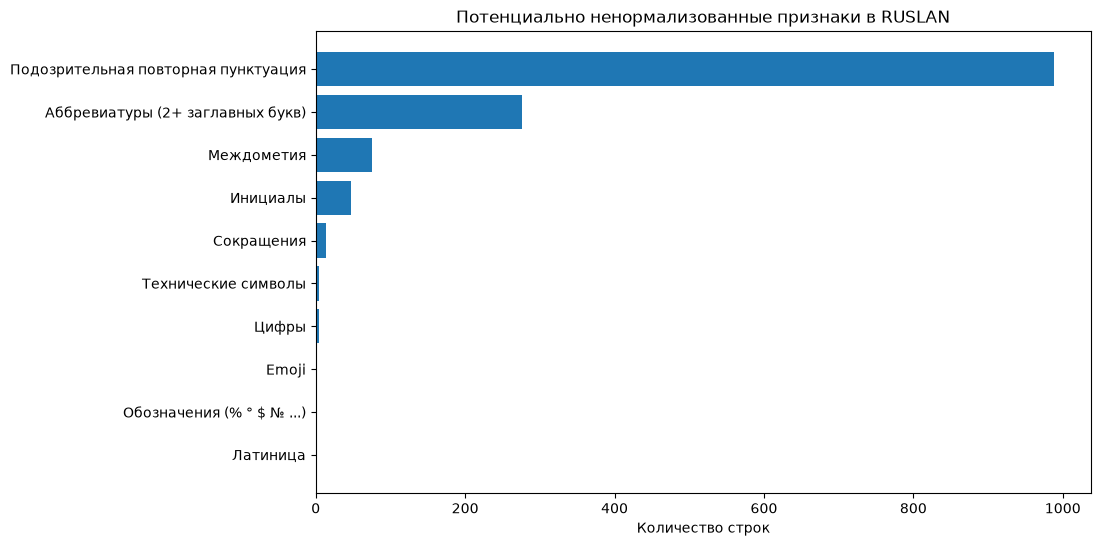

In [15]:
plot_df = eda_summary.sort_values("Строк")

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Категория"], plot_df["Строк"])
plt.xlabel("Количество строк")
plt.title("Потенциально ненормализованные признаки в RUSLAN")
plt.show()

Чаще всего сработало правило на повторную пунктуацию. Ещё встречаются сокращения, инициалы, аббревиатуры и междометия.

Цифр и технических символов мало. Но всё равно оставлю их в проверках, потому что в dev-наборе могут быть примеры, которых почти нет в самом RUSLAN.

## Примеры для каждой категории

Одних чисел мало: регулярка вполне может находить не то, что я имел в виду. Поэтому выведу реальные примеры и подсвечу совпавший кусок.

In [27]:
# ANSI-цвета для подсветки
RED = "\033[91m"
BOLD = "\033[1m"
RESET = "\033[0m"


def highlight_matches(text, pattern):
    """
    Подсвечивает все фрагменты текста,
    которые совпали с регулярным выражением.
    """
    text = str(text)

    return pattern.sub(
        lambda match: f"{RED}{BOLD}{match.group(0)}{RESET}",
        text
    )


def show_examples(df, pattern, max_n=50):
    mask = df["text"].apply(lambda text: has_pattern(text, pattern))

    examples = df.loc[mask, ["id", "text"]]
    total_count = len(examples)

    if total_count == 0:
        return None, 0

    # Если примеров меньше 50 - показываем все
    if total_count < max_n:
        return examples, total_count

    # Иначе первые 50
    return examples.head(max_n), total_count


for category, pattern in EDA_PATTERNS.items():
    examples, total_count = show_examples(
        ruslan,
        pattern,
        max_n=50
    )

    # Категории без совпадений не выводим
    if total_count == 0:
        continue

    print("=" * 100)
    print(
        f"{category}: "
        f"всего найдено {total_count}, "
        f"показано {len(examples)}"
    )
    print()

    for _, row in examples.iterrows():
        highlighted_text = highlight_matches(
            row["text"],
            pattern
        )

        print(f'[{row["id"]}] {highlighted_text}')

Цифры: всего найдено 4, показано 4

[009017_RUSLAN] Брат разъезжал по отдаленным лагерным точкам. Ему предоставили казенную машину «ГАЗ‑61». 
[011906_RUSLAN] На Филиппинах кто‑то застрелил руководителя партийной оппозиции. Под Мелитополем разбился «ТУ‑129». 
[016720_RUSLAN] В сумочке ее лежало нечто, размером чуть поболее миниатюрного дамского браунинга «Элита‑16». 
[021885_RUSLAN] – Турбовинтовой МИ‑6, – заметил Пупс, вставая. – Е‑ё! – лениво крикнул он. Затем скрестил над головой руки. 
Технические символы: всего найдено 5, показано 5

[000880_RUSLAN] Я на букву О /библиография к Окуджаве/.
[001024_RUSLAN] А Лев Уфлянд* еще больше подливает желчи, плюет на русский народ.
[004530_RUSLAN] /Например, вертухай, как вы соизволили дружески меня поименовать.
[010946_RUSLAN] Не хочу демонстрировать своего превосходства… Мы будем выше этого. Ответим ей добром на зло… О чем ты думаешь/.. 
[019204_RUSLAN] <Предисловие к книге Н.Сагаловского «Витязь в еврейской шкуре»> 
Инициалы: всего найдено 4

После просмотра примеров стало понятнее, что не всё найденное регуляркой обязательно является ошибкой.

Для себя оставлю простой принцип: если замену можно сделать однозначно - нормализую. Если вариантов чтения несколько, лучше такую строку отфильтровать.

In [31]:
for category, pattern in EDA_PATTERNS.items():

    all_matches = []

    # Собираем ВСЕ совпадения регулярки по всему датасету
    for text in ruslan["text"]:
        matches = pattern.findall(str(text))

        for match in matches:
            # Если regex содержит группы, findall может вернуть tuple
            if isinstance(match, tuple):
                match = "".join(
                    part for part in match
                    if part
                )

            match = str(match).strip()

            if match:
                all_matches.append(match)

    # Категории без совпадений пропускаем
    if not all_matches:
        continue

    counter = Counter(all_matches)

    total_matches = len(all_matches)
    unique_matches = len(counter)

    print("=" * 100)
    print(category)
    print(f"Всего срабатываний: {total_matches}")
    print(f"Уникальных значений: {unique_matches}")
    print()

    print("TOP-10:")
    for value, count in counter.most_common(10):
        print(f"{count:>6} ×  {repr(value)}")

    print()

Цифры
Всего срабатываний: 8
Уникальных значений: 4

TOP-10:
     3 ×  '6'
     3 ×  '1'
     1 ×  '2'
     1 ×  '9'

Технические символы
Всего срабатываний: 7
Уникальных значений: 4

TOP-10:
     4 ×  '/'
     1 ×  '*'
     1 ×  '<'
     1 ×  '>'

Инициалы
Всего срабатываний: 54
Уникальных значений: 49

TOP-10:
     3 ×  'Г. Друкер'
     2 ×  'И. Популовский'
     2 ×  'Г. Туронок'
     2 ×  'С. Довлатов'
     1 ×  'В. Щербаков'
     1 ×  'В. Смирнов'
     1 ×  'Н. Предлагаю'
     1 ×  'Александрову Г. П.'
     1 ×  'Е. Эткинда'
     1 ×  'К. Малышев'

Аббревиатуры (2+ заглавных букв)
Всего срабатываний: 505
Уникальных значений: 264

TOP-10:
    52 ×  'НА'
    51 ×  'СОЛО'
    51 ×  'УНДЕРВУДЕ'
     9 ×  'ЛИТО'
     8 ×  'ОВИР'
     6 ×  'КПСС'
     5 ×  'ГУЛАГ'
     4 ×  'США'
     4 ×  'УВД'
     4 ×  'НКВД'

Сокращения
Всего срабатываний: 15
Уникальных значений: 7

TOP-10:
     6 ×  'Г'
     3 ×  'Д'
     2 ×  'т. д'
     1 ×  'ул'
     1 ×  'д'
     1 ×  'г'
     1 ×  'т. е'

Междо

# Часть 2. Анализ dev-набора

## Загрузим `dev_sentences.csv`

Dev-набор используется для проверки `TextFilter`.

В нём две колонки:

- `text` - входная фраза;
- `is_normalized` - правильный ответ:
  - `1` - текст считается нормализованным;
  - `0` - текст содержит проблему.

Важно: **позитивным классом является именно `1`**.

In [18]:
assert DEV_SET_PATH is not None, "Не найден data/dev_sentences.csv"

dev = pd.read_csv(
    DEV_SET_PATH,
    sep="|",
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

print("Размер dev-набора:", dev.shape)
dev.head(10)

Размер dev-набора: (300, 2)


,text,is_normalized
0,Сегодня обещают около нуля и ветер.,1
1,Доставка займёт два-три дня.,1
2,"Так как заявка уже принята, менять ничего не н...",1
3,"Николай Николаевич, повторите, пожалуйста, сво...",1
4,Договор заключён восьмого марта две тысячи два...,1
5,Температура за окном около нуля.,1
6,"Скажите, пожалуйста, что именно не работает?((",0
7,Он приехал из Санкт-Петербурга вчера вечером???,0
8,Заявка будет рассмотрена в 3-й рабочий день.,0
9,"Дверь была приоткрыта, но входить почему-то не...",1


В dev-наборе 300 строк. Здесь специально собраны разные ошибки, поэтому для настройки фильтра он намного полезнее обычных примеров из корпуса.

## Баланс классов

Сначала посмотрю, сколько здесь нулей и единиц

,Количество
is_normalized,
0 - ненормализован,156
1 - нормализован,144


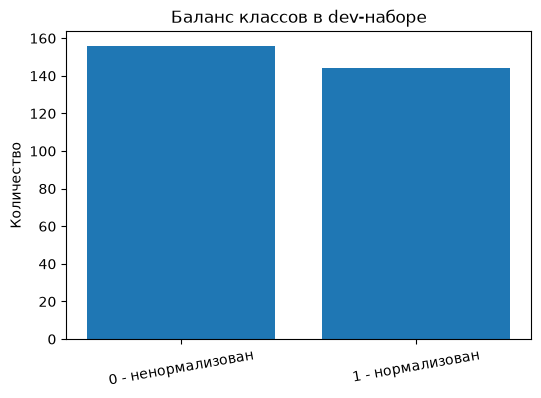

In [32]:
class_counts = (
    dev["is_normalized"]
    .value_counts()
    .sort_index()
    .rename(index={0: "0 - ненормализован", 1: "1 - нормализован"})
)

display(class_counts.to_frame("Количество"))

plt.figure(figsize=(6, 4))
plt.bar(class_counts.index, class_counts.values)
plt.ylabel("Количество")
plt.title("Баланс классов в dev-наборе")
plt.xticks(rotation=10)
plt.show()

Классы почти одинаковые по размеру: 156 строк класса 0 и 144 строки класса 1. То есть сильного перекоса здесь нет.

## Примеры из двух классов

Выведу несколько нормализованных и ненормализованных строк, чтобы было проще понять, что именно считается ошибкой.

In [33]:
print("НОРМАЛИЗОВАННЫЕ ПРИМЕРЫ:")
for text in dev.loc[dev["is_normalized"] == 1, "text"].head(8):
    print("-", text)

print("\nНЕНОРМАЛИЗОВАННЫЕ ПРИМЕРЫ:")
for text in dev.loc[dev["is_normalized"] == 0, "text"].head(12):
    print("-", text)

НОРМАЛИЗОВАННЫЕ ПРИМЕРЫ:
- Сегодня обещают около нуля и ветер.
- Доставка займёт два-три дня.
- Так как заявка уже принята, менять ничего не нужно.
- Николай Николаевич, повторите, пожалуйста, свой вопрос.
- Договор заключён восьмого марта две тысячи двадцать четвёртого года.
- Температура за окном около нуля.
- Дверь была приоткрыта, но входить почему-то не хотелось. Спасибо, что дождались ответа.
- Платёж на сумму сто пятьдесят рублей отклонён.

НЕНОРМАЛИЗОВАННЫЕ ПРИМЕРЫ:
- Скажите, пожалуйста, что именно не работает?((
- Он приехал из Санкт-Петербурга вчера вечером???
- Заявка будет рассмотрена в 3-й рабочий день.
- Я вас слушаю!!
- Осталось 8,4 ГБ интернета.
- Абонентская плата составляет 350 рублей.
- Спасибо , что дождались ответа.
- Курьер приедет на ул. Ленина после обеда.
- Обращение от г-жи Смирновой зарегистрировано.
- Обращение от госпожи Смирновой зарегистрировано <3
- Заявка принята в 20:30.
- Tариф действует c начала двадцать первого века.


По примерам видно, что дело не только в цифрах. 
Есть лишние пробелы, !! и ???, время, даты, проценты, адреса, латиница внутри русских слов, сокращения и разные специальные символы.

Поэтому одного большого регулярного выражения делать не хочется - проще собрать несколько отдельных правил.

## Проверим те же признаки на dev

Применю те же регулярки к dev-набору и посмотрю, какие из них реально попадают в класс 0.

Это пока просто проверка признаков, не сам классификатор.

In [21]:
dev_feature_rows = []

for category, pattern in EDA_PATTERNS.items():
    feature = dev["text"].apply(lambda text: has_pattern(text, pattern))

    dev_feature_rows.append({
        "Категория": category,
        "Всего найдено": int(feature.sum()),
        "Среди класса 0": int((feature & (dev["is_normalized"] == 0)).sum()),
        "Среди класса 1": int((feature & (dev["is_normalized"] == 1)).sum()),
    })

dev_features = pd.DataFrame(dev_feature_rows)
dev_features.sort_values("Всего найдено", ascending=False)

,Категория,Всего найдено,Среди класса 0,Среди класса 1
0,Цифры,69,69,0
1,Латиница,41,41,0
8,Подозрительная повторная пунктуация,20,13,7
2,Технические символы,14,14,0
3,Обозначения (% ° $ № ...),10,10,0
5,Аббревиатуры (2+ заглавных букв),9,9,0
7,Междометия,6,6,0
6,Сокращения,6,6,0
4,Инициалы,3,3,0
9,Emoji,0,0,0


Уже видно, что цифры, латиница и технические символы хорошо отделяют часть плохих строк. Но всеми такими правилами dev-набор не покрывается, поэтому после первой версии фильтра надо будет отдельно смотреть ошибки.

# Часть 3. Проверка `TextFilter`

## Оценка фильтра на dev-наборе

Этот раздел нужно запускать **после реализации `text_filter.py`**.

Пока работа над фильтром не закончена, оставим `RUN_FILTER_EVALUATION = False`.  
После реализации достаточно поменять значение на `True` и перезапустить ячейку.

Будем считать:

- `precision`;
- `recall`;
- `F1`;
- confusion matrix.

По условию лабораторной на открытом dev-наборе требуется **F1 не меньше 0.90**.

In [34]:
from text_filter import TextFilter

text_filter = TextFilter()

dev_eval = dev.copy()
dev_eval["predicted"] = dev_eval["text"].apply(text_filter.filter)

precision = precision_score(
    dev_eval["is_normalized"],
    dev_eval["predicted"],
)
recall = recall_score(
    dev_eval["is_normalized"],
    dev_eval["predicted"],
)
f1 = f1_score(
    dev_eval["is_normalized"],
    dev_eval["predicted"],
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")

cm = confusion_matrix(
    dev_eval["is_normalized"],
    dev_eval["predicted"],
)

cm_df = pd.DataFrame(
    cm,
    index=["True 0", "True 1"],
    columns=["Pred 0", "Pred 1"],
)

display(cm_df)


Precision: 0.9931
Recall:    1.0000
F1:        0.9965


,Pred 0,Pred 1
True 0,155,1
True 1,0,144


### Анализ ошибок фильтра

Одного значения F1 недостаточно. Нам важно понять, **на каких конкретных фразах ошибается правило**.

Особенно полезны два типа ошибок:

- **False Positive** - фильтр оставил плохую строку (`predicted = 1`, правильный ответ `0`);
- **False Negative** - фильтр удалил хорошую строку (`predicted = 0`, правильный ответ `1`).

После каждого серьёзного изменения регулярных выражений стоит снова смотреть эту таблицу.

In [35]:
false_positive = dev_eval[
    (dev_eval["is_normalized"] == 0)
    & (dev_eval["predicted"] == 1)
]

false_negative = dev_eval[
    (dev_eval["is_normalized"] == 1)
    & (dev_eval["predicted"] == 0)
]

print("False Positive:", len(false_positive))
display(false_positive[["text", "is_normalized", "predicted"]].head(20))

print("\nFalse Negative:", len(false_negative))
display(false_negative[["text", "is_normalized", "predicted"]].head(20))

False Positive: 1


,text,is_normalized,predicted
213,Счёт за прошлый месяц уже сформирован.,0,1



False Negative: 0


,text,is_normalized,predicted


Фильтр получился почти без ошибок:
- precision = 0.9931;
- recall = 1.0000;
- F1 = 0.9965.
  
На dev-наборе остался 1 False Positive и 0 False Negative. 

Ошибка была на строке "Счёт за прошлый месяц уже сформирован."

Требование F1 >= 0.90 выполняется с запасом.

# Часть 4. Проверка `TextNormalizer`

## Посмотрим примеры нормализации

Нормализатор должен исправлять прежде всего **безопасные текстовые артефакты**:

- разные типы кавычек;
- разные варианты дефиса;
- лишние пробелы;
- очевидно неправильные повторы пунктуации;
- Unicode-нормализацию NFC.

При этом для обучающего корпуса лучше не раскрывать неоднозначные числа и сокращения, если мы не уверены, что полученный текст будет точно соответствовать аудио.

In [24]:
RUN_NORMALIZER_EXAMPLES = True

normalizer_examples = [
    "Расстреливать надо таких писателей!.",
    "«Пример цитаты»",
    "де‑факто",
    "Спасибо , что дождались ответа.",
    "Давайте начнём сначала..",
    "Он приехал вчера!!!",
]

if RUN_NORMALIZER_EXAMPLES:
    from text_normalizer import TextNormalizer

    normalizer = TextNormalizer()

    examples_df = pd.DataFrame({
        "raw": normalizer_examples,
        "normalized": [
            normalizer.normalize(text)
            for text in normalizer_examples
        ],
    })

    display(examples_df)
else:
    print(
        "Примеры нормализатора пока пропущены. "
        "После реализации text_normalizer.py установите "
        "RUN_NORMALIZER_EXAMPLES = True."
    )

,raw,normalized
0,Расстреливать надо таких писателей!.,Расстреливать надо таких писателей!
1,«Пример цитаты»,"""Пример цитаты"""
2,де‑факто,де-факто
3,"Спасибо , что дождались ответа.","Спасибо, что дождались ответа."
4,Давайте начнём сначала..,Давайте начнём сначала.
5,Он приехал вчера!!!,Он приехал вчера!


На примерах нормализатор делает ожидаемые простые замены: приводит кавычки и дефисы к одному виду, убирает лишний пробел перед запятой и повторную пунктуацию.

Отдельно важно, чтобы при этом не пропали ё и знак ударения, а итоговая строка оставалась в NFC.

# Часть 5. Итоговый файл

## Проверка `metadata_RUSLAN_22200_normalized.csv`

После реализации `TextNormalizer` и `TextFilter` запускается:

```bash
python preprocess_ruslan.py
```

Он должен создать файл с тремя колонками:

```text
id | raw text | normalized text
```

Ниже подготовлена проверка итогового файла. Если файл ещё не создан, ячейка просто сообщит об этом.

In [36]:
if NORMALIZED_PATH is not None:
    cleaned = pd.read_csv(
        NORMALIZED_PATH,
        sep="|",
        names=["id", "raw", "normalized"],
        encoding="utf-8",
        quoting=csv.QUOTE_NONE,
    )

    print("Количество сохранённых строк:", len(cleaned))
    print("Количество колонок:", cleaned.shape[1])
    print("Пропуски:")
    display(cleaned.isna().sum().to_frame("Количество"))

    changed = (cleaned["raw"] != cleaned["normalized"]).sum()
    print("Строк изменено нормализатором:", changed)
    print("Строк исключено фильтром:", len(ruslan) - len(cleaned))

    nfc_ok = cleaned["normalized"].apply(
        lambda text: unicodedata.is_normalized("NFC", str(text))
    ).all()

    print("Все normalized-тексты в NFC:", nfc_ok)

    display(cleaned.head(10))
else:
    print(
        "Итоговый файл пока не найден. "
        "Сначала запустите preprocess_ruslan.py."
    )

Количество сохранённых строк: 21951
Количество колонок: 3
Пропуски:


,Количество
id,0
raw,0
normalized,0


Строк изменено нормализатором: 15891
Строк исключено фильтром: 249
Все normalized-тексты в NFC: True


,id,raw,normalized
0,000000_RUSLAN,С тревожным чувством берусь я за перо.,С тревожным чувством берусь я за перо.
1,000001_RUSLAN,Кого интересуют признания литературного неудач...,Кого интересуют признания литературного неудач...
2,000002_RUSLAN,Что поучительного в его исповеди?,Что поучительного в его исповеди?
3,000003_RUSLAN,Да и жизнь моя лишена внешнего трагизма.,Да и жизнь моя лишена внешнего трагизма.
4,000004_RUSLAN,Я абсолютно здоров.,Я абсолютно здоров.
5,000005_RUSLAN,У меня есть любящая родня.,У меня есть любящая родня.
6,000006_RUSLAN,"Мне всегда готовы предоставить работу, которая...","Мне всегда готовы предоставить работу, которая..."
7,000007_RUSLAN,"Мало того, я обладаю преимуществами.","Мало того, я обладаю преимуществами."
8,000008_RUSLAN,Мне без труда удается располагать к себе людей.,Мне без труда удается располагать к себе людей.
9,000009_RUSLAN,"Я совершил десятки поступков, уголовно наказуе...","Я совершил десятки поступков, уголовно наказуе..."


Сколько данных осталось

In [40]:
before = len(ruslan)
after_filter = len(cleaned)

removed = before - after_filter
changed = (cleaned["raw"] != cleaned["normalized"]).sum()
unchanged = after_filter - changed

print(f"Было строк: {before}")
print(f"После фильтрации: {after_filter} ({after_filter / before * 100:.2f}% корпуса)")
print(f"Удалено фильтром: {removed} ({removed / before * 100:.2f}% корпуса)")
print()
print(f"После нормализации: {after_filter} строк")
print(f"Изменено нормализатором: {changed} ({changed / after_filter * 100:.2f}% от оставшихся)")
print(f"Не изменилось: {unchanged} ({unchanged / after_filter * 100:.2f}% от оставшихся)")


Было строк: 22200
После фильтрации: 21951 (98.88% корпуса)
Удалено фильтром: 249 (1.12% корпуса)

После нормализации: 21951 строк
Изменено нормализатором: 15891 (72.39% от оставшихся)
Не изменилось: 6060 (27.61% от оставшихся)


## Финальтная проверка

Перед сдачей проверю минимальные требования::

- сохранено не менее 16 000 фраз;
- в файле ровно три колонки;
- нет пропусков;
- нормализованный текст находится в NFC.


In [38]:
if NORMALIZED_PATH is not None:
    assert len(cleaned) >= 16_000, "После фильтрации осталось меньше 16 000 строк"
    assert cleaned.shape[1] == 3, "В итоговом файле должно быть ровно 3 колонки"
    assert not cleaned.isna().any().any(), "В итоговом файле есть пропуски"
    assert nfc_ok, "Не все normalized-тексты находятся в NFC"

    print("Основные формальные проверки пройдены.")
else:
    print("Финальные проверки станут доступны после создания итогового CSV.")

Основные формальные проверки пройдены.


# Выводы

В RUSLAN было 22 200 строк. Пропусков и пустых строк не оказалось, id везде уникальные. Повторяющийся текст есть, но я его не удалял, потому что записи относятся к разным аудиофайлам.
По EDA чаще всего встречалась необычная повторная пунктуация. Ещё нашлись инициалы, сокращения, аббревиатуры, междометия и несколько строк с цифрами или техническими символами.
На dev-наборе получилось:
- precision = 0.9931;
- recall = 1.0000;
- F1 = 0.9965;
- 1 False Positive и 0 False Negative.
  
После полной обработки осталось 21 951 строка: фильтр убрал 249 строк. Нормализатор изменил 15 891 строку. Все итоговые строки находятся в NFC, формальные проверки проходят.

